# Aggregation: Sum

This notebook is a deep-dive on transformations for computing the sum with bounded stability.

---
Any functions that have not completed the proof-writing and vetting process may still be accessed if you opt-in to "contrib".
Please contact us if you are interested in proof-writing. Thank you!

In [1]:
import opendp.prelude as dp

dp.enable_features("contrib")

## Known/Unknown Dataset Size
Constructing a sum transformation is easy!
First, describe the metric space you are working in. 
This can also be filled in from the previous transformation.

In [2]:
# the space of all integer vectors,
# where distances between vectors are measured by the symmetric distance
input_space = dp.vector_domain(dp.atom_domain(bounds=(0, 10))), dp.symmetric_distance()

Then construct the sum transformation:

In [3]:
sum_trans = input_space >> dp.t.then_sum()

# compute the sum
assert sum_trans([1, 2, 4]) == 7  # 1 + 2 + 4

# compute the sensitivity
assert sum_trans.map(d_in=1) == 10  # d_in * max(abs(L), abs(U), U - L)

If the dataset size is public information, then restrict the input space:

In [4]:
# the space of all length-3 integer vectors,
# where distances between vectors are measured by the symmetric distance
input_space = (
    dp.vector_domain(dp.atom_domain(bounds=(-10, 10)), size=3),
    dp.symmetric_distance(),
)
sum_trans = input_space >> dp.t.then_sum()

# compute the sum
assert sum_trans([1, 2, 4]) == 7  # 1 + 2 + 4

# compute the sensitivity
assert sum_trans.map(d_in=2) == 20  # (d_in // 2) * (U - L)

Since the sensitivity is scaled by $U - L$, the sensitivity won't increase if you shift both bounds by the same fixed constant. Therefore, the sensitivity remains small in situations where $L$ and $U$ share the same sign and are large in magnitude.

These examples use a `d_in` in terms of the `SymmetricDistance`.
However, when the dataset size is known, we are operating in the bounded-DP regime where adjacent datasets have the same size.
This means it takes both an addition and a removal to change any single record, to reach any adjacent dataset.
This results in a stair-step relationship between $d_{in}$ and $d_{out}$:

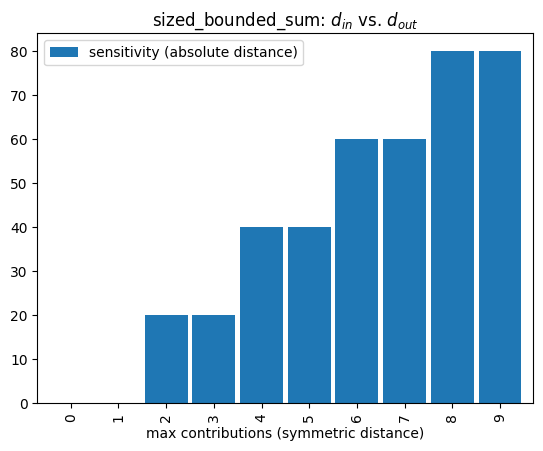

In [5]:
import pandas as pd

pd.DataFrame(
    [(d_in, sum_trans.map(d_in)) for d_in in range(10)],
    columns=[
        "max contributions (symmetric distance)",
        "sensitivity (absolute distance)",
    ],
).plot.bar(0, title="sized_bounded_sum: $d_{in}$ vs. $d_{out}$", width=0.9);

Intuitively, if we say the symmetric distance between adjacent datasets is at most one, and all adjacent datasets differ by an even number of additions and removals, then the sensitivity is zero.

## Floating-Point

Floating-point addition is not closed, that is, 
adding two floating point numbers doesn't necessarily result in another floating-point number.
To resolve this, the IEEE-754 floating-point standard requires a rounding to the nearest floating-point number.
Unfortunately, this influences the sensitivity of the summation.

In the OpenDP Library, stability maps account for the increased sensitivity due to floating-point rounding in intermediate operations by adding an additional constant term that scales with the dataset size.

In [6]:
input_space = (
    dp.vector_domain(dp.atom_domain(bounds=(-10.0, 10.0), nan=False), size=1000),
    dp.symmetric_distance(),
)
sum_trans = input_space >> dp.t.then_sum()

# The sensitivity is now slightly larger than 20 because of the floating-point constant term
print(sum_trans.map(d_in=2))

20.000000000022208


Unfortunately, the worst-case sensitivity analysis hits a snag when the dataset size is unknown, as the rounding error becomes unbounded.

To keep the sensitivity finite, a dataset truncation operation is applied first:
The dataset size is reduced to no greater than $2^{20}$ elements (a little over 1 million records), if necessary, via a simple random sample.

The dataset truncation also causes a regression in the sensitivity, as it it is now scaled by $max(|L|, U, U - L)$. 
This accounts for the case where an adjacent dataset with one additional row needs to drop a random row to preserve the dataset size.
In practice, the worst-case penalty on the sensitivity is when $L = -U$. 

In [7]:
# show the worst-case degradation
input_space = (
    dp.vector_domain(dp.atom_domain(bounds=(-10.0, 10.0), nan=False)),
    dp.symmetric_distance(),
)
sum_trans = input_space >> dp.t.then_sum()

# the sensitivity is now scaled by max(|L|, |U|, U - L) = max(|-10.|, |10.|, 10. - -10.) = 20.
print(sum_trans.map(d_in=1))

20.000000046566132


If the bounds share the same sign, then the sensitivity remains unchanged, save for the constant term to account for float rounding.

In [8]:
# if the bounds share sign, the sensitivity is unaffected
input_space = (
    dp.vector_domain(dp.atom_domain(bounds=(-10.0, 0.0), nan=False)),
    dp.symmetric_distance(),
)
sum_trans = input_space >> dp.t.then_sum()

# the sensitivity is now scaled by max(|L|, |U|, U - L) = max(|-10.|, |0.|, 0. - -10.) = 10.
print(sum_trans.map(d_in=1))

10.00000004656613


## Pairwise Floating-Point Summation

Floating-point sums use pairwise summation:

In [9]:
dp.t.make_sum(
    dp.vector_domain(dp.atom_domain(bounds=(-10.0, 0.0), nan=False)),
    dp.symmetric_distance(),
).map(d_in=1)

/var/folders/mq/0sn8snd12rng58mbr6wws53m0000gq/T/ipykernel_2660/3261295572.py:1: DeprecationWarning: Call to deprecated function (or staticmethod) make_sum. (Use Polars or NumPy aggregation APIs instead.) -- Deprecated since version 0.16.0.
  dp.t.make_sum(


10.00000004656613

The size of the relaxation term varies according to the dataset size, magnitude of the bounds, summation algorithm and floating-point bit depth.
The following visualization shows the effect of dataset size on pairwise rounding relaxation.

To isolate the relaxation term for this visualization, the sensitivity is calculated for the case when datasets differ by zero additions or removals.
A dataset with the same rows but a different row ordering will result in a different answer for the same sum query.

/var/folders/mq/0sn8snd12rng58mbr6wws53m0000gq/T/ipykernel_2660/993661760.py:8: DeprecationWarning: Call to deprecated function (or staticmethod) make_sum. (Use Polars or NumPy aggregation APIs instead.) -- Deprecated since version 0.16.0.
  dp.t.make_sum(


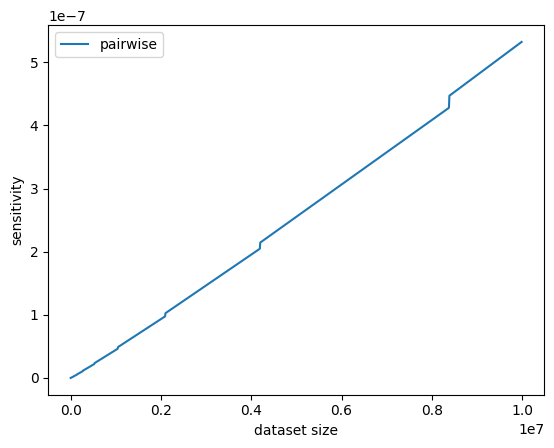

In [10]:
bounds = (0.0, 10.0)
sizes = list(range(1, 10_000_000, 10_000))

pd.DataFrame(
    {
        "dataset size": sizes,
        "pairwise": [
            dp.t.make_sum(
                dp.vector_domain(dp.atom_domain(bounds=bounds, nan=False), size=size),
                dp.symmetric_distance(),
            ).map(0)
            for size in sizes
        ],
    }
).plot(0, ylabel="sensitivity");  # type: ignore

The increase to sensitivity grows on the order of $O(n \log_2(n))$.

Beware, these relaxation terms grow far more quickly when the data type is adjusted to single-precision floats (`f32`)!


## Integer Summation

Unsized integer sums truncate at the maximum safe length derived from the bounds and integer type. Ordered inputs use a prefix; unordered inputs use a uniform sample. Sensitivity is scaled by $max(|L|, |U|, U-L)$.

With `i32` bounds `[0, 2**30]`, the safe retained length is one, so this ordered sum retains only its first record:


In [11]:
sum_trans = dp.t.make_sum(
    dp.vector_domain(dp.atom_domain(bounds=(0, 2**30))),
    dp.insert_delete_distance(),
)
assert sum_trans([2**30, 2**30]) == 2**30
sum_trans

/var/folders/mq/0sn8snd12rng58mbr6wws53m0000gq/T/ipykernel_2660/2475605071.py:1: DeprecationWarning: Call to deprecated function (or staticmethod) make_sum. (Use Polars or NumPy aggregation APIs instead.) -- Deprecated since version 0.16.0.
  sum_trans = dp.t.make_sum(


Transformation(
    input_domain   = VectorDomain(AtomDomain(bounds=[0, 1073741824], T=i32)),
    output_domain  = AtomDomain(T=i32),
    input_metric   = InsertDeleteDistance(),
    output_metric  = AbsoluteDistance(i32))

For exact-size vectors, the constructor rejects potential overflow instead of truncating.

In [12]:
dp.t.make_sum(
    dp.vector_domain(dp.atom_domain(bounds=(-2, 4), T="i32"), size=1234),
    dp.symmetric_distance(),
)

/var/folders/mq/0sn8snd12rng58mbr6wws53m0000gq/T/ipykernel_2660/1036005465.py:1: DeprecationWarning: Call to deprecated function (or staticmethod) make_sum. (Use Polars or NumPy aggregation APIs instead.) -- Deprecated since version 0.16.0.
  dp.t.make_sum(


Transformation(
    input_domain   = VectorDomain(AtomDomain(bounds=[-2, 4], T=i32), size=1234),
    output_domain  = AtomDomain(T=i32),
    input_metric   = SymmetricDistance(),
    output_metric  = AbsoluteDistance(i32))